# MLP_JK_11 — Projection comparison: PCA vs. PLS vs. a learned layer

**Why this notebook:** Dr. Ardekani asked us to justify PCA. Every model so far shrinks the 4,608-number GenBio-PathFM embedding with PCA before the MLP. PCA ignores the genes. Here we test two projections that use the genes, and what each one costs.

**The projections** (each one turns 4,608 numbers into k numbers)

| Method | How | Uses the genes? |
|---|---|---|
| **PCA** (current) | StandardScaler → PCA k | No |
| **PLS** | StandardScaler → PLS with k components, with the 50 genes as targets. Computed with kernel PLS (Dayal & MacGregor, 1997), which gives the same components as sklearn's `PLSRegression` but much faster | Yes |
| **Learned** | StandardScaler → `Linear(4608, k)`, trained together with the MLP head (learning rate 3e-4, like the head). It starts as the PCA k projection, so it only moves away from PCA if training helps | Yes |
| **Learned slow** | the same, but the projection learns 10× more slowly (3e-5; the head stays at 3e-4) | Yes |

In MLP_JK_Best the PCA scores go into the head **unscaled**, so the PLS scores go in unscaled too, and the learned layer starts at the unscaled PCA scores.

**Everything else is MLP_JK_Best:** setup E (the spot's own embedding and its 5×5 neighborhood average, **one projection per block**, so the head gets 2k numbers), RAW target, V_clean genes, the same folds, validation groups, MLP head, training, shrinkage and seeds. Only the projection changes. GenBio stays frozen.

**Grid:** k = 32, 64, 128, 256, 512 for each method.

**No leakage:** PLS and the learned layer use the genes, so they never see the patients they are scored on. For validation scores they are fit on the inner-training patients only; for test scores on the fold's training patients only.

**Choosing:** the best k per method by **validation PCC** only. A setting would replace MLP_JK_Best only if validation PCC > 0.2376 and validation NRMSE ≤ 1.1128 (the mean predictor's). This notebook reports that; it does **not** change MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `~/JHU/BDD/MLP_JK/results/` (standard_gene_rule.json, gene_symbols.csv, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_11/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors
import platform
import subprocess
import threading
import psutil
from sklearn.cross_decomposition import PLSRegression

## Settings

**Paths:** `RULE_FILE` (V_clean), `SYMBOLS_FILE`, `BEST_DIR` (MLP_JK_Best's saved scores and genes), `LOG_RESULTS` (whether rows are added to `all_results.csv`).

**The grid:** `METHODS`, `K_GRID`, and `K_MAX` (PLS is fit once with 512 components and the first k are used). `PROJECTION_LR`: the learning rate of the learned projection for each learned method (the head always uses `LEARNING_RATE`).

**Checks:** `SKLEARN_CHECK_K` (kernel PLS is compared with sklearn's PLS at this k on fold 0), `SKLEARN_SETTINGS` (default sklearn, and sklearn run to convergence), and the tolerances: for reproducing MLP_JK_Best, for the PLS features (relative difference or correlation with sklearn's), and for the validation PCC with each PLS version.

**sklearn PLS timings:** `SKLEARN_PLS_MEASURED` are one sklearn `PLSRegression` fit on fold 0's training spots (center block), measured on this Mac before this notebook was written. They are only used in the cost table, to show what off-the-shelf PLS would cost.

**Everything else** is the same as MLP_JK_Best.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
RESULTS_DIR = os.path.join(MLP_DIR, "results")
RULE_FILE = os.path.join(RESULTS_DIR, "standard_gene_rule.json")
SYMBOLS_FILE = os.path.join(RESULTS_DIR, "gene_symbols.csv")
BEST_DIR = os.path.join(RESULTS_DIR, "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_11"
LOG_RESULTS = True
OUT_DIR = os.path.join(RESULTS_DIR, NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(RESULTS_DIR, "all_results.csv")

METHODS = ["PCA", "PLS", "Learned", "Learned slow"]
PROJECTION_LR = {"Learned": 3e-4, "Learned slow": 3e-5}
K_GRID = [32, 64, 128, 256, 512]
K_MAX = max(K_GRID)
SKLEARN_CHECK_K = 32
SKLEARN_PLS_MEASURED = {16: 12.5, 32: 31.7, 64: 95.2}

N_FOLDS = 4
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"5x5": 3.0}

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
PROJECTION_WEIGHT_DECAY = 0.0
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_MSE_TOLERANCE = 0.005
CHECK_PCC_TOLERANCE = 0.01
CHECK_VAL_PCC_TOLERANCE = 0.005
PLS_FEATURE_REL_TOLERANCE = 2e-4
PLS_MIN_CORRELATION = 0.9999
PLS_VAL_PCC_TOLERANCE = 0.005
SKLEARN_SETTINGS = {"default": {}, "converged": {"tol": 1e-12, "max_iter": 20000}}
LEARNED_START_TOLERANCE = 1e-3

The gene rule, the device, fixed seeds, and the hardware this runs on (for the cost table). The Apple GPU (`mps`) isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
with open(RULE_FILE) as f:
    gene_rule = json.load(f)
EXCLUDE_PREFIX = gene_rule["exclude_prefix"]
MIN_DETECTION = gene_rule["min_detection"]
N_GENES = gene_rule["n_genes"]
GENE_LIST = gene_rule["name"]
print(f"Gene list {GENE_LIST}: exclude '{EXCLUDE_PREFIX}...', detection >= {MIN_DETECTION}, top {N_GENES} by variance")

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")


def sysctl(name):
    try:
        return subprocess.run(["sysctl", "-n", name], capture_output=True, text=True).stdout.strip()
    except OSError:
        return "unknown"


hardware = {
    "machine": sysctl("hw.model"),
    "chip": sysctl("machdep.cpu.brand_string"),
    "cpu_cores": os.cpu_count(),
    "memory_GB": round(psutil.virtual_memory().total / 1e9, 1),
    "os": platform.platform(),
    "device": str(device),
    "torch": torch.__version__,
}
print("Hardware:", hardware)

Gene list V_clean: exclude '__...', detection >= 0.1, top 50 by variance
Hardware: {'machine': 'Mac17,3', 'chip': 'Apple M5', 'cpu_cores': 10, 'memory_GB': 17.2, 'os': 'macOS-27.2.1-arm64-arm-64bit', 'device': 'mps', 'torch': '2.13.0'}


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and patient folds (copied from MLP_JK_03)

The 5×5 neighborhood: every spot on the same section within 3.0 spot spacings, including the spot itself. Folds: `GroupKFold` by patient, the same 4 folds as always.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 3. The gene list, V_clean, from the rule file

The same as MLP_JK_Best: per fold, on training spots only, drop the excluded bins, keep genes with count > 0 in at least 10% of the spots, take the top 50 by variance. The lists must equal MLP_JK_Best's genes in every fold.

In [7]:
symbols = pd.read_csv(SYMBOLS_FILE)
symbol_of = dict(zip(symbols["ensembl_id"], symbols["symbol"]))
is_excluded = np.char.startswith(all_genes.astype(str), EXCLUDE_PREFIX)


def standard_genes(train_index):
    Y_train = Y[train_index]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_excluded & (detection >= MIN_DETECTION))[0]
    return candidates[np.argsort(variance[candidates])[::-1][:N_GENES]]


fold_genes = [standard_genes(fold_train_index[fold]) for fold in range(N_FOLDS)]

reference_genes = pd.read_csv(os.path.join(BEST_DIR, "genes.csv"))
for fold in range(N_FOLDS):
    saved = reference_genes[reference_genes["fold"] == fold].sort_values("rank")["ensembl_id"].tolist()
    assert saved == list(all_genes[fold_genes[fold]]), f"fold {fold}: genes differ from MLP_JK_Best"
print("V_clean equals MLP_JK_Best's genes in every fold.")
for fold in range(N_FOLDS):
    print(f"fold {fold}: " + ", ".join(symbol_of[g] for g in all_genes[fold_genes[fold]][:10]) + ", ...")

V_clean equals MLP_JK_Best's genes in every fold.
fold 0: IGLL5, TFF3, MUC1, RPS3, S100A9, H2AJ, MGP, ERBB2, KRT19, NHERF1, ...
fold 1: TFF3, IGLL5, S100A9, ERBB2, NHERF1, MUC1, COX6C, MGP, KRT19, B2M, ...
fold 2: TFF3, IGLL5, RPS3, ERBB2, KRT19, MUC1, MGP, NHERF1, H2AJ, AZGP1, ...
fold 3: TFF3, IGLL5, RPS3, ERBB2, H2AJ, MUC1, MGP, KRT19, NHERF1, S100A9, ...


## Step 4. Scoring and the error split

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`error_parts`** (from MLP_JK_06): a fold's MSE split into **level error** (each test slide's predicted mean vs. its true mean) and **pattern error** (what's left inside each slide). It checks that the two add up to the MSE.

In [8]:
def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()

## Step 5. The MLP head and training (copied from MLP_JK_Best)

**The head:** Linear(2k, 128) → ReLU → Dropout 0.3 → Linear(128, 50). Adam lr 3e-4, MSE loss on standardized genes, batches of 256, early stopping with patience 10 on validation patients. `shrink` = `train_mean + s × (prediction − train_mean)`; the shrinkage factor is called **s** here, so it doesn't clash with k.

**The only change to `train_mlp`:** it can take a `make_model` function, so the learned projection can be trained together with the head. Parameters whose name starts with `projection` get weight decay 0 and their own learning rate (`projection_lr`: 3e-4 for Learned, 3e-5 for Learned slow); the head keeps weight decay 1e-3 and learning rate 3e-4. Without `make_model` it builds the same MLP as MLP_JK_Best with one parameter group, so PCA and PLS train exactly as before.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed, make_model=None,
              projection_lr=LEARNING_RATE):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    if make_model is None:
        model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    else:
        model = make_model().to(device)
    projection = [p for name, p in model.named_parameters() if name.startswith("projection")]
    head = [p for name, p in model.named_parameters() if not name.startswith("projection")]
    groups = [{"params": head, "weight_decay": WEIGHT_DECAY}]
    if projection:
        groups.append({"params": projection, "weight_decay": PROJECTION_WEIGHT_DECAY, "lr": projection_lr})
    optimizer = torch.optim.Adam(groups, lr=LEARNING_RATE)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 6. Measuring cost

- **Time:** `time.perf_counter()` around each step. Work on the Apple GPU runs asynchronously, so `torch.mps.synchronize()` is called before the clock stops.
- **Peak memory:** `PeakMemory` reads the process's **resident memory (RSS, via psutil)** every 50 ms in a background thread, and reports the peak above where it started. On Apple's unified memory, GPU allocations may not show up in RSS, so for the GPU runs the memory the GPU driver holds (`torch.mps.driver_allocated_memory()`) is recorded too, right after training. The GPU cache is emptied at the start of every run, so this number belongs to that run only.

In [10]:
class PeakMemory:
    def __enter__(self):
        self.process = psutil.Process()
        self.start = self.process.memory_info().rss
        self.peak = self.start
        self.running = True
        self.thread = threading.Thread(target=self.watch, daemon=True)
        self.thread.start()
        return self

    def watch(self):
        while self.running:
            self.peak = max(self.peak, self.process.memory_info().rss)
            time.sleep(0.05)

    def __exit__(self, *args):
        self.running = False
        self.thread.join()
        self.peak = max(self.peak, self.process.memory_info().rss)
        self.peak_MB = (self.peak - self.start) / 1e6


def sync():
    if device.type == "mps":
        torch.mps.synchronize()


def gpu_MB():
    return torch.mps.driver_allocated_memory() / 1e6 if device.type == "mps" else np.nan

## Step 7. The three projections

**Standardized embeddings.** For each fold, one StandardScaler per block (center, 5×5 average), fit on the fold's training spots, as in MLP_JK_Best. All three methods start from these.

**PCA** (`fit_pca`): PCA with k components per block, fit on the fold's training spots, exactly as MLP_JK_Best's `pca_256` (each k is a separate fit). PCA uses no genes, so (as in MLP_JK_Best) it may include the inner validation patients.

**PLS** (`kernel_pls_fit`, `kernel_pls_transform`): partial least squares finds directions in the embedding that covary most with the 50 genes. sklearn's `PLSRegression` builds them by repeatedly passing over all spots, which takes minutes to hours at large k. **Kernel PLS** (Dayal & MacGregor, 1997) is the same algorithm (it gives the same components), but it works from two small summaries of the data, `XᵀX` (4,608 × 4,608) and `XᵀY` (4,608 × 50), so it's fast at any k. Everything follows sklearn: the embedding and the genes are centered and scaled on the fit spots (`scale=True`), each component's direction is the top direction of the remaining `XᵀY`, with sklearn's sign rule (its largest entry positive), and new spots are projected with sklearn's "rotations". Components are built one at a time and don't depend on how many come after, so one fit with 512 components gives every k (the first k columns).

**What happens to the projected numbers before the head:** in MLP_JK_Best, nothing: the PCA scores go into the head **unscaled** (no StandardScaler or other step on the scores). So the PLS scores also go into the head unscaled, and the learned layer starts exactly at the unscaled PCA scores.

**Learned** and **Learned slow** (`ProjectedMLP`): per block, a linear layer 4,608 → k (weights `W`, bias `b`), then the same head. It starts at PCA: `W` = the PCA directions, `b` = −(PCA mean) · `W`ᵀ, so at epoch 0 its output equals the PCA scores. It's built from fixed numbers (no random draws), so the head starts from the same random weights as the PCA run with the same seed. The two versions differ only in the projection's learning rate.

In [11]:
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])


def standardize(fold):
    train_index = fold_train_index[fold]
    blocks = {}
    for block, X in [("center", X_raw), ("mean_5x5", X_mean_5x5)]:
        scaler = StandardScaler()
        scaler.fit(X[train_index])
        blocks[block] = scaler.transform(X).astype(np.float32)
    return blocks


def fit_pca(Z, train_index, k):
    pca = PCA(n_components=k, random_state=SEED)
    pca.fit(Z[train_index])
    return pca


def kernel_pls_fit(X, Y, n_components):
    start = time.perf_counter()
    x_mean = X.mean(axis=0)
    x_sd = X.std(axis=0, ddof=1)
    x_sd[x_sd == 0] = 1.0
    Xs = ((X - x_mean) / x_sd).astype(np.float64)
    y_sd = Y.std(axis=0, ddof=1)
    y_sd[y_sd == 0] = 1.0
    Ys = (Y - Y.mean(axis=0)) / y_sd
    XtX = Xs.T @ Xs
    XtY = Xs.T @ Ys
    del Xs
    setup_seconds = time.perf_counter() - start

    n_features = X.shape[1]
    weights = np.zeros((n_features, n_components))
    rotations = np.zeros((n_features, n_components))
    loadings = np.zeros((n_features, n_components))
    seconds_after = np.zeros(n_components)
    for a in range(n_components):
        eigenvalues, eigenvectors = np.linalg.eigh(XtY.T @ XtY)
        w = XtY @ eigenvectors[:, -1]
        w /= np.linalg.norm(w)
        w *= np.sign(w[np.argmax(np.abs(w))])
        r = w - rotations[:, :a] @ (loadings[:, :a].T @ w)
        XtX_r = XtX @ r
        tt = r @ XtX_r
        p = XtX_r / tt
        q = XtY.T @ r / tt
        XtY -= tt * np.outer(p, q)
        weights[:, a] = w
        rotations[:, a] = r
        loadings[:, a] = p
        seconds_after[a] = time.perf_counter() - start
    return {"mean": x_mean, "sd": x_sd, "weights": weights, "rotations": rotations,
            "setup_seconds": setup_seconds, "seconds_after": seconds_after}


def kernel_pls_transform(fit, Z, k):
    return (((Z - fit["mean"]) / fit["sd"]) @ fit["rotations"][:, :k]).astype(np.float32)


class ProjectedMLP(nn.Module):
    def __init__(self, center_start, average_start, n_hidden, n_outputs, dropout):
        super().__init__()
        k, n_inputs = center_start[0].shape
        self.n_inputs = n_inputs
        self.head = MLP(2 * k, n_hidden, n_outputs, dropout)
        self.projection_center_weight = nn.Parameter(torch.tensor(center_start[0], dtype=torch.float32))
        self.projection_center_bias = nn.Parameter(torch.tensor(center_start[1], dtype=torch.float32))
        self.projection_average_weight = nn.Parameter(torch.tensor(average_start[0], dtype=torch.float32))
        self.projection_average_bias = nn.Parameter(torch.tensor(average_start[1], dtype=torch.float32))

    def project(self, x):
        center = x[:, :self.n_inputs] @ self.projection_center_weight.T + self.projection_center_bias
        average = x[:, self.n_inputs:] @ self.projection_average_weight.T + self.projection_average_bias
        return torch.cat([center, average], dim=1)

    def forward(self, x):
        return self.head(self.project(x))


def pca_start(pca):
    weight = pca.components_.astype(np.float32)
    return weight, (-pca.mean_ @ pca.components_.T).astype(np.float32)


def count_weights(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Step 8. One method, one k, one fold

The same as MLP_JK_Best, with the projection plugged in. Where each projection is fit:

| Method | For the 4 validation groups | For the test fold |
|---|---|---|
| PCA | the fold's PCA (training patients; no genes), as in MLP_JK_Best | the same |
| PLS | **refit on that group's fit patients only** (the validation patients never touch it) | refit on all the fold's training patients |
| Learned, Learned slow | trained with the head on the group's fit patients | trained with the head on all the fold's training patients |

`s` and the number of epochs are chosen on the 4 validation groups (validation NRMSE, then the median best epoch), then 3 final seeds are trained and averaged.

**Cost recorded per run:** MLP training time (4 validation runs + 3 final runs), the GPU driver's memory after training, the trainable weights (projection + head), the size of the features the head reads, and the time to predict 1,000 test spots (projection + head; for PCA and PLS the projection runs on the CPU).

In [12]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def projected_features(method, k, fold_data, rows):
    if method == "PCA":
        pcas = fold_data["pca"][k]
        return np.concatenate([pcas[block].transform(fold_data["Z"][block]).astype(np.float32)
                               for block in ["center", "mean_5x5"]], axis=1)
    if method in ["PLS", "PLS_sklearn"]:
        fits = fold_data[method][rows]
        if method == "PLS":
            return np.concatenate([kernel_pls_transform(fits[block], fold_data["Z"][block], k)
                                   for block in ["center", "mean_5x5"]], axis=1)
        return np.concatenate([fits[block].transform(fold_data["Z"][block]).astype(np.float32)
                               for block in ["center", "mean_5x5"]], axis=1)
    raise ValueError(method)


def run_fold(method, k, fold, fold_data, validation_only=False):
    if device.type == "mps":
        torch.mps.empty_cache()
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_test = Y[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)

    make_model = None
    projection_lr = PROJECTION_LR.get(method, LEARNING_RATE)
    if method in PROJECTION_LR:
        P_device = to_device(np.concatenate([fold_data["Z"]["center"], fold_data["Z"]["mean_5x5"]], axis=1))
        center_start = pca_start(fold_data["pca"][k]["center"])
        average_start = pca_start(fold_data["pca"][k]["mean_5x5"])
        make_model = lambda: ProjectedMLP(center_start, average_start, HIDDEN_SIZE, N_GENES, DROPOUT)
    elif method == "PCA":
        P_device = to_device(projected_features("PCA", k, fold_data, None))

    mlp_seconds = 0.0
    val_rows = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        if method in ["PLS", "PLS_sklearn"]:
            P_device = to_device(projected_features(method, k, fold_data, group))
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {"fold": fold, "test_index": val_index, "genes": genes, "y_test": y_fold[val_index],
                      "y_mean": np.tile(fit_mean, (len(val_index), 1)), "alpha": no_alpha}
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        start = time.perf_counter()
        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED, make_model, projection_lr)
        sync()
        mlp_seconds += time.perf_counter() - start
        val_pred = predict(trained, P_device, val_index)
        for s in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, s)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({"method": method, "k": k, "fold": fold, "val_group": group, "s": s,
                             "val_PCC": scores["PCC"].mean(), "val_NRMSE": scores["NRMSE"].mean(),
                             "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                             "best_epoch": trained["best_epoch"]})

    val_table = pd.DataFrame(val_rows)
    by_s = val_table.groupby("s").agg(val_PCC=("val_PCC", "mean"), val_NRMSE=("val_NRMSE", "mean"),
                                      val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
                                      epochs=("best_epoch", "median")).reset_index()
    chosen = by_s.loc[by_s["val_NRMSE"].idxmin()].to_dict()
    chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
    chosen.update({"method": method, "k": k, "fold": fold})
    if validation_only:
        del P_device
        return chosen

    if method in ["PLS", "PLS_sklearn"]:
        P_device = to_device(projected_features(method, k, fold_data, "final"))
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        start = time.perf_counter()
        final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number,
                          make_model, projection_lr)
        sync()
        mlp_seconds += time.perf_counter() - start
        seed_predictions.append(predict(final, P_device, test_index))
        if seed_number == 0:
            first_model = final

    test_spots = len(test_index)
    start = time.perf_counter()
    if method == "PCA":
        features = np.concatenate([fold_data["pca"][k][block].transform(fold_data["Z"][block][test_index])
                                   for block in ["center", "mean_5x5"]], axis=1).astype(np.float32)
    elif method == "PLS":
        features = np.concatenate([kernel_pls_transform(fold_data["PLS"]["final"][block], fold_data["Z"][block][test_index], k)
                                   for block in ["center", "mean_5x5"]], axis=1)
    else:
        features = np.concatenate([fold_data["Z"]["center"][test_index], fold_data["Z"]["mean_5x5"][test_index]], axis=1)
    features_device = to_device(features)
    first_model["model"].eval()
    with torch.no_grad():
        first_model["model"](features_device)
    sync()
    predict_seconds = time.perf_counter() - start

    cost = {
        "method": method, "k": k, "fold": fold,
        "mlp_seconds": mlp_seconds,
        "mlp_runs": N_VAL_GROUPS + N_FINAL_SEEDS,
        "trainable_weights": count_weights(first_model["model"]),
        "feature_MB": len(spots) * 2 * k * 4 / 1e6,
        "input_MB_on_GPU": P_device.numel() * 4 / 1e6,
        "gpu_driver_MB": gpu_MB(),
        "predict_ms_per_1000_spots": 1000 * predict_seconds / test_spots * 1000,
    }
    del P_device, features_device, first_model, final

    test_result = {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                   "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["s"]), "alpha": no_alpha}
    seed_results = [dict(test_result, y_pred=shrink(p, train_mean, chosen["s"])) for p in seed_predictions]
    mean_result = dict(test_result, y_pred=np.tile(train_mean, (test_spots, 1)))
    return test_result, seed_results, mean_result, val_table, chosen, cost

## Step 9. Preparing one fold

`prepare_fold` builds everything a fold needs and records what it costs:
- the standardized embeddings (both blocks);
- PCA for each k (both blocks), with fit time and peak memory;
- kernel PLS with 512 components for each of the 5 sets of rows (the 4 inner-training sets and the fold's full training set), both blocks, using the fold's 50 genes as targets. The fit time for k components is measured inside the fit (the `XᵀX` setup plus the first k components).

`pls_rows` lets the reproduction check skip the PLS fits.

In [13]:
def prepare_fold(fold, ks=K_GRID, pls_rows=True):
    train_index = fold_train_index[fold]
    fold_data = {"Z": standardize(fold), "pca": {}, "PLS": {}}
    fit_costs = []

    for k in ks:
        with PeakMemory() as memory:
            start = time.perf_counter()
            fold_data["pca"][k] = {block: fit_pca(fold_data["Z"][block], train_index, k) for block in ["center", "mean_5x5"]}
            seconds = time.perf_counter() - start
        fit_costs.append({"method": "PCA", "k": k, "fold": fold, "projection_fit_seconds": seconds,
                          "projection_fits": 2, "fit_peak_RSS_MB": memory.peak_MB})

    if pls_rows:
        y_genes = Y[:, fold_genes[fold]].toarray()
        row_sets = {group: fit_rows for group, (fit_rows, _) in enumerate(validation_groups(train_index))}
        row_sets["final"] = train_index
        seconds_by_k = {k: 0.0 for k in ks}
        peak = 0.0
        for name, rows in row_sets.items():
            fold_data["PLS"][name] = {}
            for block in ["center", "mean_5x5"]:
                with PeakMemory() as memory:
                    fit = kernel_pls_fit(fold_data["Z"][block][rows], y_genes[rows], K_MAX)
                fold_data["PLS"][name][block] = fit
                peak = max(peak, memory.peak_MB)
                for k in ks:
                    seconds_by_k[k] += fit["seconds_after"][k - 1]
        for k in ks:
            fit_costs.append({"method": "PLS", "k": k, "fold": fold, "projection_fit_seconds": seconds_by_k[k],
                              "projection_fits": 2 * len(row_sets), "fit_peak_RSS_MB": peak})
    return fold_data, fit_costs


results = {}
seed_results = {}
mean_results = []
val_tables = []
chosen_rows = []
cost_rows = []
fit_cost_rows = []


def store(method, k, fold, output):
    test_result, seeds, mean_result, val_table, chosen, cost = output
    results.setdefault((method, k), []).append(test_result)
    seed_results.setdefault((method, k), [[] for _ in range(N_FINAL_SEEDS)])
    for seed_number, seed_result in enumerate(seeds):
        seed_results[(method, k)][seed_number].append(seed_result)
    if method == "PCA" and k == 256:
        mean_results.append(mean_result)
    val_tables.append(val_table)
    chosen_rows.append(chosen)
    cost_rows.append(cost)

## Step 10. Checks on fold 0 (before the grid)

1. **PLS slicing:** a kernel PLS fit with 32 components must equal the first 32 columns of a fit with 512 (on fold 0's training spots).
2. **Learned layer starts at PCA:** at epoch 0, the learned layer's output on every spot must equal the PCA k=256 features. Float32 rounding on the GPU gives differences around 1e-4 or less; anything near 1e-2 would be a real mismatch, and the notebook stops.
3. **Kernel PLS = sklearn PLS** (k = 32, fold 0, both blocks, each fit on the fit patients of each validation group):
   - (a) **The features:** the kernel PLS features of every spot are compared with sklearn `PLSRegression`'s `transform`, component by component. The signs are aligned first (a PLS component can come out flipped). Default sklearn PLS stops slightly before convergence on later components; kernel PLS gives the converged solution. So this check uses sklearn run to convergence (`tol=1e-12`, `max_iter=20000`). It passes if the largest difference is within 2e-4 of the feature scale (the largest |feature|), **or** every component's correlation with sklearn's is above 0.9999. The numbers against default sklearn are recorded too (`pls_check.csv`).
   - (b) **The validation PCC** of the head trained on each version (kernel PLS vs. **default** sklearn, the version people actually run; same seed) must agree within 0.005.
   - If either fails, the notebook stops. The sklearn fit times are recorded for the cost table.

In [14]:
fold_data, fit_costs = prepare_fold(0)
fit_cost_rows.extend(fit_costs)
train_index = fold_train_index[0]
y_genes = Y[:, fold_genes[0]].toarray()

small = kernel_pls_fit(fold_data["Z"]["center"][train_index], y_genes[train_index], 32)
large = fold_data["PLS"]["final"]["center"]
slice_difference = np.abs(small["rotations"] - large["rotations"][:, :32]).max()
print(f"1. PLS slicing: max |difference| between a 32-component fit and the first 32 of 512 = {slice_difference:.2e}")
assert slice_difference < 1e-8, "PLS components depend on the number of components. Stop."

model = ProjectedMLP(pca_start(fold_data["pca"][256]["center"]), pca_start(fold_data["pca"][256]["mean_5x5"]),
                     HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
Z_device = to_device(np.concatenate([fold_data["Z"]["center"], fold_data["Z"]["mean_5x5"]], axis=1))
with torch.no_grad():
    learned_start = torch.cat([model.project(Z_device[i:i + 4096]) for i in range(0, len(spots), 4096)]).cpu().numpy()
pca_features = projected_features("PCA", 256, fold_data, None)
start_difference = np.abs(learned_start - pca_features).max()
print(f"2. Learned layer at epoch 0 vs. PCA k=256 features: max |difference| = {start_difference:.2e} "
      f"(largest |PCA feature| = {np.abs(pca_features).max():.1f})")
assert start_difference < LEARNED_START_TOLERANCE, "The learned layer doesn't start at PCA. Stop."
del model, Z_device, learned_start

fold_data["PLS_sklearn"] = {}
sklearn_rows = []
feature_rows = []
for group, (fit_rows, _) in enumerate(validation_groups(train_index)):
    fold_data["PLS_sklearn"][group] = {}
    for block in ["center", "mean_5x5"]:
        ours = kernel_pls_transform(fold_data["PLS"][group][block], fold_data["Z"][block], SKLEARN_CHECK_K).astype(np.float64)
        for setting, options in SKLEARN_SETTINGS.items():
            with PeakMemory() as memory:
                start = time.perf_counter()
                sklearn_pls = PLSRegression(n_components=SKLEARN_CHECK_K, **options).fit(
                    fold_data["Z"][block][fit_rows], y_genes[fit_rows])
                seconds = time.perf_counter() - start
            if setting == "default":
                fold_data["PLS_sklearn"][group][block] = sklearn_pls
            sklearn_rows.append({"sklearn": setting, "group": group, "block": block, "spots": len(fit_rows),
                                 "seconds": seconds, "peak_RSS_MB": memory.peak_MB})

            theirs = sklearn_pls.transform(fold_data["Z"][block]).astype(np.float64)
            correlations = np.array([np.corrcoef(ours[:, c], theirs[:, c])[0, 1] for c in range(SKLEARN_CHECK_K)])
            aligned = ours * np.sign(correlations)
            feature_rows.append({"sklearn": setting, "group": group, "block": block,
                                 "max_abs_difference": np.abs(aligned - theirs).max(),
                                 "feature_scale": np.abs(theirs).max(),
                                 "relative_difference": np.abs(aligned - theirs).max() / np.abs(theirs).max(),
                                 "lowest_correlation": np.abs(correlations).min(),
                                 "components_below_0.9999": int(np.sum(np.abs(correlations) < PLS_MIN_CORRELATION)),
                                 "components_flipped": int(np.sum(correlations < 0))})
sklearn_check_fits = pd.DataFrame(sklearn_rows)
feature_check = pd.DataFrame(feature_rows)
converged = feature_check[feature_check["sklearn"] == "converged"]
features_ok = bool((converged["relative_difference"] <= PLS_FEATURE_REL_TOLERANCE).all()
                   or (converged["lowest_correlation"] > PLS_MIN_CORRELATION).all())
fit_seconds = sklearn_check_fits.groupby("sklearn")["seconds"].mean()
print(f"   sklearn PLS k={SKLEARN_CHECK_K}: {fit_seconds['default']:.1f} s per fit (default), "
      f"{fit_seconds['converged']:.1f} s (converged); kernel PLS: {large['seconds_after'][SKLEARN_CHECK_K - 1]:.1f} s per fit")
print(f"\n3a. PLS features, kernel PLS vs. sklearn (k = {SKLEARN_CHECK_K}, signs aligned):")
print(feature_check.to_string(index=False, float_format=lambda x: f"{x:.3g}"))
print(f"    passes (against converged sklearn): {features_ok}")

kernel_chosen = run_fold("PLS", SKLEARN_CHECK_K, 0, fold_data, validation_only=True)
sklearn_chosen = run_fold("PLS_sklearn", SKLEARN_CHECK_K, 0, fold_data, validation_only=True)
val_difference = kernel_chosen["val_PCC"] - sklearn_chosen["val_PCC"]
pls_check = pd.DataFrame([
    {"version": "kernel PLS (numpy)", "val_PCC": kernel_chosen["val_PCC"], "val_NRMSE": kernel_chosen["val_NRMSE"], "s": kernel_chosen["s"]},
    {"version": "sklearn PLSRegression", "val_PCC": sklearn_chosen["val_PCC"], "val_NRMSE": sklearn_chosen["val_NRMSE"], "s": sklearn_chosen["s"]},
])
print(f"\n3b. Validation PCC, fold 0, k = {SKLEARN_CHECK_K}:")
print(pls_check.round(4).to_string(index=False))
print(f"    difference {val_difference:+.4f} (must be within {PLS_VAL_PCC_TOLERANCE})")
assert features_ok, "Kernel PLS features don't match sklearn's. Stop."
assert abs(val_difference) <= PLS_VAL_PCC_TOLERANCE, "Kernel PLS and sklearn PLS disagree on validation PCC. Stop."
print("Kernel PLS reproduces sklearn PLSRegression.")
del fold_data["PLS_sklearn"]

1. PLS slicing: max |difference| between a 32-component fit and the first 32 of 512 = 0.00e+00
2. Learned layer at epoch 0 vs. PCA k=256 features: max |difference| = 2.21e-04 (largest |PCA feature| = 77.8)
   sklearn PLS k=32: 31.2 s per fit (default), 68.7 s (converged); kernel PLS: 3.9 s per fit

3a. PLS features, kernel PLS vs. sklearn (k = 32, signs aligned):
  sklearn  group    block  max_abs_difference  feature_scale  relative_difference  lowest_correlation  components_below_0.9999  components_flipped
  default      0   center               0.771             50               0.0154               0.999                        9                   1
converged      0   center             0.00184             50             3.68e-05                   1                        0                   0
  default      0 mean_5x5                1.56           63.8               0.0244               0.997                       11                   0
converged      0 mean_5x5             0.00317 

## Step 11. PCA k = 256 must reproduce MLP_JK_Best

PCA with k = 256 is exactly MLP_JK_Best. It runs on all 4 folds first. Test MSE must be within 0.005, pooled and within-patient PCC within 0.01, NRMSE within 0.005, and validation PCC within 0.005 of MLP_JK_Best, or the notebook stops. Differences are shown.

In [15]:
def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "model": model_name, "fold": fold, "MSE": mse, "level_error": level_error,
            "pattern_error": pattern_error, "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    folds["level_share"] = folds["level_error"] / folds["MSE"]
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within



fold_0_data = fold_data
start_time = time.time()
for fold in range(N_FOLDS):
    if fold == 0:
        fold_data = fold_0_data
    else:
        fold_data, _ = prepare_fold(fold, ks=[256], pls_rows=False)
    with PeakMemory() as memory:
        output = run_fold("PCA", 256, fold, fold_data)
    output[5]["run_peak_RSS_MB"] = memory.peak_MB
    store("PCA", 256, fold, output)
    print(f"PCA k=256, fold {fold} done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if fold > 0:
        del fold_data

best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv")).set_index("model").loc["E 5x5 average"]
_, pca_overall, _, _ = score_results(results[("PCA", 256)], "PCA k=256")
pca_chosen = pd.DataFrame([c for c in chosen_rows if c["method"] == "PCA" and c["k"] == 256])
pca_overall["val_PCC"] = pca_chosen["val_PCC"].mean()
check_rows = []
for metric, tolerance in [("val_PCC", CHECK_VAL_PCC_TOLERANCE), ("test_MSE", CHECK_MSE_TOLERANCE),
                          ("pooled_PCC", CHECK_PCC_TOLERANCE), ("within_PCC", CHECK_PCC_TOLERANCE),
                          ("NRMSE", CHECK_MSE_TOLERANCE)]:
    check_rows.append({"metric": metric, "PCA_k256": pca_overall[metric], "MLP_JK_Best": best_summary[metric],
                       "difference": pca_overall[metric] - best_summary[metric], "tolerance": tolerance,
                       "ok": abs(pca_overall[metric] - best_summary[metric]) <= tolerance})
reproduction_check = pd.DataFrame(check_rows)
print(reproduction_check.round(4).to_string(index=False))
assert reproduction_check["ok"].all(), "PCA k=256 doesn't reproduce MLP_JK_Best. Stop and check before the grid."
print("PCA k=256 reproduces MLP_JK_Best.")

PCA k=256, fold 0 done (0.2 min)
PCA k=256, fold 1 done (0.6 min)
PCA k=256, fold 2 done (1.1 min)
PCA k=256, fold 3 done (1.5 min)
    metric  PCA_k256  MLP_JK_Best  difference  tolerance   ok
   val_PCC    0.2376       0.2376         0.0      0.005 True
  test_MSE    0.9451       0.9451        -0.0      0.005 True
pooled_PCC    0.2053       0.2053         0.0      0.010 True
within_PCC    0.1731       0.1731         0.0      0.010 True
     NRMSE    1.0673       1.0673         0.0      0.005 True
PCA k=256 reproduces MLP_JK_Best.


## Step 12. The full grid

For every fold: prepare the fold once (standardized embeddings, PCA for every k, kernel PLS for every set of rows), then run every method and k. PCA k = 256 is already done (Step 11). Fold 0's data from Step 10 is reused.

In [16]:
start_time = time.time()
for fold in range(N_FOLDS):
    if fold == 0:
        fold_data = fold_0_data
        del fold_0_data
    else:
        fold_data, fit_costs = prepare_fold(fold)
        fit_cost_rows.extend(fit_costs)
    print(f"fold {fold}: projections ready ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    for method in METHODS:
        for k in K_GRID:
            if method == "PCA" and k == 256:
                continue
            with PeakMemory() as memory:
                output = run_fold(method, k, fold, fold_data)
            output[5]["run_peak_RSS_MB"] = memory.peak_MB
            store(method, k, fold, output)
            if device.type == "mps":
                torch.mps.empty_cache()
        print(f"fold {fold}: {method} done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    del fold_data

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows).sort_values(["method", "k", "fold"]).reset_index(drop=True)
print("Grid done.")

fold 0: projections ready (0.0 min)
fold 0: PCA done (1.0 min)
fold 0: PLS done (2.9 min)
fold 0: Learned done (5.7 min)
fold 0: Learned slow done (9.4 min)
fold 1: projections ready (11.2 min)
fold 1: PCA done (12.1 min)
fold 1: PLS done (13.7 min)
fold 1: Learned done (16.0 min)
fold 1: Learned slow done (19.4 min)
fold 2: projections ready (21.1 min)
fold 2: PCA done (21.9 min)
fold 2: PLS done (23.5 min)
fold 2: Learned done (26.2 min)
fold 2: Learned slow done (29.5 min)
fold 3: projections ready (31.2 min)
fold 3: PCA done (32.1 min)
fold 3: PLS done (33.6 min)
fold 3: Learned done (36.7 min)
fold 3: Learned slow done (40.3 min)
Grid done.


## Step 13. Results

**Per method and k:** validation PCC and NRMSE (what choices are based on), and test MSE, MSE ratio (÷ the mean predictor's MSE), pooled PCC, within-patient PCC and NRMSE (genes with test SD < 0.05 excluded, as before), plus the level/pattern split. Per fold in `fold_scores.csv`, together with the chosen `s`, the number of training epochs of the final models (`final_epochs`) and each validation group's best epoch (`val_best_epochs`). **Seed spread** = the range over the 3 final seeds.

In [17]:
mean_folds, mean_overall, _, _ = score_results(mean_results, "mean predictor")
summary_rows = [{"method": "mean predictor", "k": np.nan, "test_MSE": mean_overall["test_MSE"], "MSE_ratio": 1.0,
                 "NRMSE": mean_overall["NRMSE"], "level_error": mean_overall["level_error"],
                 "pattern_error": mean_overall["pattern_error"], "level_share": mean_overall["level_share"]}]
fold_tables = []
for method in METHODS:
    for k in K_GRID:
        folds, overall, _, _ = score_results(results[(method, k)], f"{method} k={k}")
        folds["MSE_ratio"] = folds["MSE"].to_numpy() / mean_folds["MSE"].to_numpy()
        folds.insert(0, "k", k)
        folds.insert(0, "method", method)
        fold_tables.append(folds)
        c = chosen_settings[(chosen_settings["method"] == method) & (chosen_settings["k"] == k)]
        row = {"method": method, "k": k}
        row.update(overall)
        row["MSE_ratio"] = overall["test_MSE"] / mean_overall["test_MSE"]
        row["val_PCC"] = c["val_PCC"].mean()
        row["val_NRMSE"] = c["val_NRMSE"].mean()
        row["val_mean_predictor_NRMSE"] = c["val_mean_predictor_NRMSE"].mean()
        row["chosen_s"] = "/".join(str(s) for s in c["s"])
        row["final_epochs"] = "/".join(str(e) for e in c["final_epochs"])
        seed_overall = [score_results(seed_results[(method, k)][n], "seed")[1] for n in range(N_FINAL_SEEDS)]
        for metric in ["test_MSE", "pooled_PCC", "within_PCC"]:
            values = [o[metric] for o in seed_overall]
            row[f"seed_range_{metric}"] = max(values) - min(values)
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
fold_scores = pd.concat(fold_tables, ignore_index=True)
epochs = chosen_settings[["method", "k", "fold", "final_epochs", "s"]].copy()
epochs["val_best_epochs"] = [
    "/".join(str(e) for e in val_scores[(val_scores["method"] == row.method) & (val_scores["k"] == row.k)
                                        & (val_scores["fold"] == row.fold)].drop_duplicates("val_group")["best_epoch"])
    for row in epochs.itertuples()]
fold_scores = fold_scores.merge(epochs, on=["method", "k", "fold"], how="left")

pd.set_option("display.width", 250)
columns = ["method", "k", "val_PCC", "val_NRMSE", "test_MSE", "MSE_ratio", "pooled_PCC", "within_PCC", "NRMSE",
           "chosen_s", "level_share", "seed_range_pooled_PCC"]
print(summary[columns].round(4).to_string(index=False))
print()
for column, title in [("PCC", "Pooled PCC"), ("PCC_within", "Within-patient PCC"), ("MSE_ratio", "MSE ratio")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot_table(index=["method", "k"], columns="fold", values=column).round(4).to_string())
    print()

        method     k  val_PCC  val_NRMSE  test_MSE  MSE_ratio  pooled_PCC  within_PCC  NRMSE        chosen_s  level_share  seed_range_pooled_PCC
mean predictor   NaN      NaN        NaN    0.9987     1.0000         NaN         NaN 1.0980             NaN       0.5925                    NaN
           PCA  32.0   0.2267     1.0813    0.9430     0.9442      0.2229      0.1811 1.0668 0.4/0.4/0.4/0.4       0.5856                 0.0105
           PCA  64.0   0.2156     1.0893    0.9445     0.9457      0.2081      0.1803 1.0661 0.2/0.4/0.4/0.4       0.5865                 0.0177
           PCA 128.0   0.2208     1.0850    0.9532     0.9544      0.2113      0.1716 1.0724 0.4/0.2/0.4/0.4       0.5883                 0.0035
           PCA 256.0   0.2376     1.0804    0.9451     0.9463      0.2053      0.1731 1.0673 0.4/0.4/0.4/0.4       0.5873                 0.0136
           PCA 512.0   0.2276     1.0854    0.9367     0.9379      0.2363      0.1849 1.0633 0.4/0.4/0.4/0.4       0.5860         

**Best k per method (by validation PCC only), the level/pattern split for it, and the best check.** A setting would become the new Best only if validation PCC > 0.2376 (MLP_JK_Best's) **and** validation NRMSE ≤ the mean predictor's (1.1128). This notebook only reports it.

In [18]:
best_val_pcc = pd.read_csv(os.path.join(BEST_DIR, "summary.csv")).set_index("model").loc["E 5x5 average", "val_PCC"]
best_rows = []
for method in METHODS:
    rows = summary[summary["method"] == method]
    row = rows.loc[rows["val_PCC"].idxmax()]
    passes = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
    best_rows.append({
        "method": method, "best_k": int(row["k"]), "val_PCC": row["val_PCC"], "val_NRMSE": row["val_NRMSE"],
        "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"], "passes_NRMSE_rule": passes,
        "current_best_val_PCC": best_val_pcc, "would_beat_best": bool(passes and row["val_PCC"] > best_val_pcc),
        "test_MSE": row["test_MSE"], "pooled_PCC": row["pooled_PCC"], "within_PCC": row["within_PCC"],
        "level_error": row["level_error"], "pattern_error": row["pattern_error"], "level_share": row["level_share"],
    })
best_check = pd.DataFrame(best_rows)
best_check["note"] = "report only; MLP_JK_Best is not changed by this notebook"
print(best_check.drop(columns="note").round(4).to_string(index=False))
print(f"\nMean predictor: level error {mean_overall['level_error']:.4f}, pattern error {mean_overall['pattern_error']:.4f}")
if best_check["would_beat_best"].any():
    print("At least one setting passes the rule. MLP_JK_Best is NOT changed here; this is for review.")
else:
    print("No setting passes the rule. MLP_JK_Best is unchanged.")

      method  best_k  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  current_best_val_PCC  would_beat_best  test_MSE  pooled_PCC  within_PCC  level_error  pattern_error  level_share
         PCA     256   0.2376     1.0804                    1.1128               True                0.2376             True    0.9451      0.2053      0.1731       0.5550         0.3901       0.5873
         PLS      32   0.2385     1.0767                    1.1128               True                0.2376             True    0.9369      0.2529      0.1762       0.5442         0.3927       0.5808
     Learned      32   0.2164     1.0936                    1.1128               True                0.2376            False    0.9588      0.2445      0.1869       0.5658         0.3930       0.5901
Learned slow     512   0.2247     1.0847                    1.1128               True                0.2376            False    0.9373      0.2399      0.1880       0.5503         0.3870       0.5871


## Step 14. Cost

Per method and k, summed or averaged over the 4 folds:
- `projection_fit_seconds`: PCA = the PCA fits; PLS = the kernel PLS fits (10 per fold: 2 blocks × 5 sets of rows); Learned and Learned slow = the **extra** MLP training time compared with PCA at the same k (the layer is trained, not fit).
- `mlp_seconds_total`, `mlp_seconds_per_run` (7 runs per fold: 4 validation + 3 final), `total_seconds` = projection + MLP.
- `trainable_weights`: projection + head (PCA and PLS: the head only).
- `feature_MB`: the projected features for all 30,600 spots (2k numbers each, float32). For Learned, the head reads 2k numbers too, but the input kept on the GPU is the full standardized embedding (`input_MB_on_GPU`).
- `fit_peak_RSS_MB` (PCA, PLS: during the projection fit) and `run_peak_RSS_MB` (during training and prediction), via psutil; `gpu_driver_MB` = the GPU driver's memory after training.
- `predict_ms_per_1000_spots`: projection + head forward for the test spots.

**sklearn PLS rows:** what off-the-shelf `PLSRegression` would cost per fit, from the timings measured on this Mac before this notebook (k = 16, 32, 64; fold 0 training spots, one block; default settings) and from the k = 32 fits in Step 10 (default and converged). Larger k is **extrapolated** with a power law fitted to the measured times (marked `extrapolated`). A full run needs 40 fits per k (10 per fold).

In [19]:
costs = pd.DataFrame(cost_rows)
fit_costs = pd.DataFrame(fit_cost_rows)
pca_mlp = costs[costs["method"] == "PCA"].set_index(["k", "fold"])["mlp_seconds"]
for method in PROJECTION_LR:
    learned = costs[costs["method"] == method].set_index(["k", "fold"])
    learned_fit = (learned["mlp_seconds"] - pca_mlp.reindex(learned.index)).clip(lower=0).reset_index(name="projection_fit_seconds")
    learned_fit["method"] = method
    learned_fit["projection_fits"] = 0
    fit_costs = pd.concat([fit_costs, learned_fit], ignore_index=True)
costs = costs.merge(fit_costs, on=["method", "k", "fold"], how="left")

cost_summary = costs.groupby(["method", "k"]).agg(
    projection_fit_seconds=("projection_fit_seconds", "sum"),
    projection_fits=("projection_fits", "sum"),
    mlp_seconds_total=("mlp_seconds", "sum"),
    mlp_runs=("mlp_runs", "sum"),
    trainable_weights=("trainable_weights", "first"),
    feature_MB=("feature_MB", "first"),
    input_MB_on_GPU=("input_MB_on_GPU", "first"),
    fit_peak_RSS_MB=("fit_peak_RSS_MB", "max"),
    run_peak_RSS_MB=("run_peak_RSS_MB", "max"),
    gpu_driver_MB=("gpu_driver_MB", "max"),
    predict_ms_per_1000_spots=("predict_ms_per_1000_spots", "mean"),
).reset_index()
cost_summary["mlp_seconds_per_run"] = cost_summary["mlp_seconds_total"] / cost_summary["mlp_runs"]
cost_summary["total_seconds"] = cost_summary["projection_fit_seconds"] + cost_summary["mlp_seconds_total"]
cost_summary["timing"] = "measured"
cost_summary.loc[cost_summary["method"] == "PLS", "method"] = "PLS (kernel)"

measured_k = np.array(sorted(SKLEARN_PLS_MEASURED))
measured_seconds = np.array([SKLEARN_PLS_MEASURED[k] for k in measured_k])
slope, intercept = np.polyfit(np.log(measured_k), np.log(measured_seconds), 1)
sklearn_rows = []
for k in sorted(set(K_GRID) | set(SKLEARN_PLS_MEASURED)):
    measured = k in SKLEARN_PLS_MEASURED
    per_fit = SKLEARN_PLS_MEASURED[k] if measured else float(np.exp(intercept) * k ** slope)
    sklearn_rows.append({"method": "sklearn PLS (one fit, fold 0 training spots)", "k": k,
                         "seconds_per_fit": per_fit, "projection_fit_seconds": per_fit * 10 * N_FOLDS,
                         "projection_fits": 10 * N_FOLDS,
                         "timing": "measured" if measured else f"extrapolated (time ~ k^{slope:.2f})"})
for setting, rows in sklearn_check_fits.groupby("sklearn"):
    sklearn_rows.append({"method": f"sklearn PLS, {setting} (Step 10 check, inner-training spots)", "k": SKLEARN_CHECK_K,
                         "seconds_per_fit": rows["seconds"].mean(), "fit_peak_RSS_MB": rows["peak_RSS_MB"].max(),
                         "timing": "measured"})
cost_table = pd.concat([cost_summary, pd.DataFrame(sklearn_rows)], ignore_index=True)

show = ["method", "k", "timing", "projection_fit_seconds", "mlp_seconds_total", "mlp_seconds_per_run", "total_seconds",
        "trainable_weights", "feature_MB", "input_MB_on_GPU", "fit_peak_RSS_MB", "run_peak_RSS_MB", "gpu_driver_MB",
        "predict_ms_per_1000_spots", "seconds_per_fit"]
print(cost_table[show].round(2).to_string(index=False))
print("\nHardware:", hardware)

                                                      method   k                       timing  projection_fit_seconds  mlp_seconds_total  mlp_seconds_per_run  total_seconds  trainable_weights  feature_MB  input_MB_on_GPU  fit_peak_RSS_MB  run_peak_RSS_MB  gpu_driver_MB  predict_ms_per_1000_spots  seconds_per_fit
                                                     Learned  32                     measured                   64.48             126.15                 4.51         190.63           309746.0        7.83          1128.04              NaN          1621.77        2273.08                      24.18              NaN
                                                     Learned  64                     measured                   69.06             119.24                 4.26         188.30           612914.0       15.67          1128.04              NaN          2178.06        2298.25                      28.46              NaN
                                                     Learn

## Step 15. Plots

**Figure 1:** validation PCC (solid) and test pooled PCC (dashed) vs. k, one color per method. The grey line is MLP_JK_Best's validation PCC.

**Figure 2:** test pooled PCC vs. total time (projection + MLP, all 4 folds), one point per method and k (log scale).

**Figure 3:** validation NRMSE (solid) and test NRMSE (dashed) vs. k. The grey lines are the mean predictor's (validation dotted, test dash-dot).

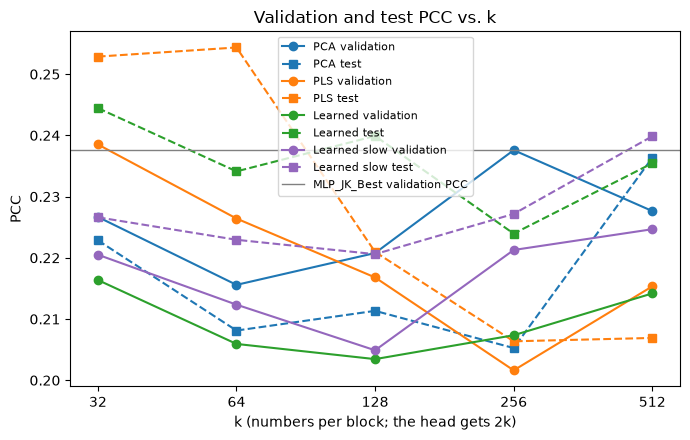

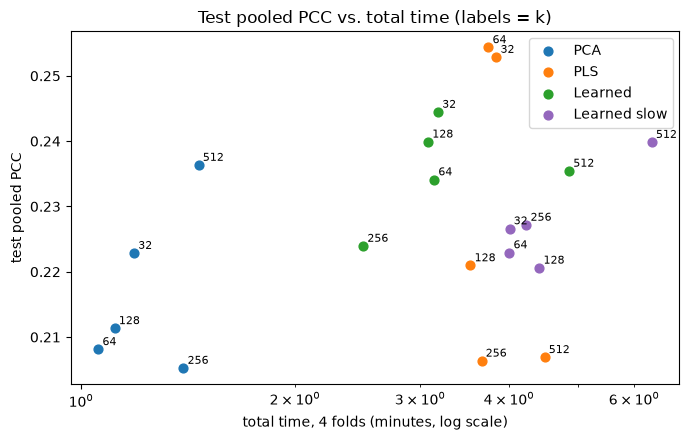

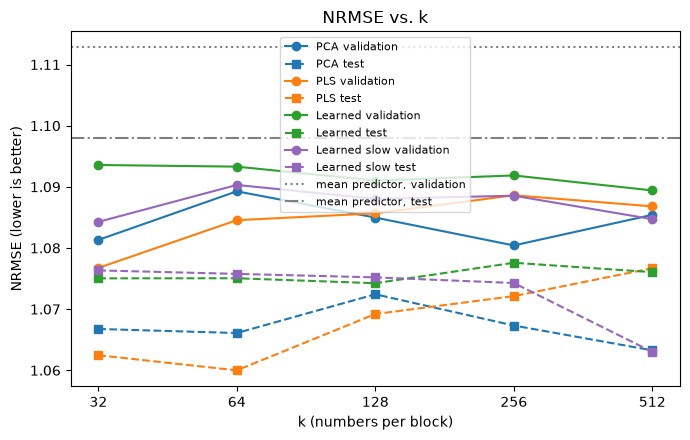

In [20]:
method_colors = {"PCA": "tab:blue", "PLS": "tab:orange", "Learned": "tab:green", "Learned slow": "tab:purple"}
rows = summary[summary["method"].isin(METHODS)]

fig, ax = plt.subplots(figsize=(7, 4.5))
for method in METHODS:
    r = rows[rows["method"] == method]
    ax.plot(r["k"], r["val_PCC"], marker="o", color=method_colors[method], label=f"{method} validation")
    ax.plot(r["k"], r["pooled_PCC"], marker="s", linestyle="--", color=method_colors[method], label=f"{method} test")
ax.axhline(best_val_pcc, color="grey", linewidth=1, label="MLP_JK_Best validation PCC")
ax.set_xscale("log", base=2)
ax.set_xticks(K_GRID)
ax.set_xticklabels(K_GRID)
ax.set_xlabel("k (numbers per block; the head gets 2k)")
ax.set_ylabel("PCC")
ax.set_title("Validation and test PCC vs. k")
ax.legend(fontsize=8)
plt.tight_layout()
save_figure("1_pcc_vs_k.png")
plt.show()

timing = cost_summary.copy()
timing["method"] = timing["method"].replace({"PLS (kernel)": "PLS"})
timing = timing.merge(rows[["method", "k", "pooled_PCC"]], on=["method", "k"])
fig, ax = plt.subplots(figsize=(7, 4.5))
for method in METHODS:
    t = timing[timing["method"] == method]
    ax.scatter(t["total_seconds"] / 60, t["pooled_PCC"], color=method_colors[method], s=40, label=method)
    for _, point in t.iterrows():
        ax.annotate(f"{int(point['k'])}", (point["total_seconds"] / 60, point["pooled_PCC"]), fontsize=8,
                    xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("total time, 4 folds (minutes, log scale)")
ax.set_ylabel("test pooled PCC")
ax.set_title("Test pooled PCC vs. total time (labels = k)")
ax.legend()
plt.tight_layout()
save_figure("2_pcc_vs_time.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for method in METHODS:
    r = rows[rows["method"] == method]
    ax.plot(r["k"], r["val_NRMSE"], marker="o", color=method_colors[method], label=f"{method} validation")
    ax.plot(r["k"], r["NRMSE"], marker="s", linestyle="--", color=method_colors[method], label=f"{method} test")
ax.axhline(rows["val_mean_predictor_NRMSE"].mean(), color="grey", linestyle=":", label="mean predictor, validation")
ax.axhline(mean_overall["NRMSE"], color="grey", linestyle="-.", label="mean predictor, test")
ax.set_xscale("log", base=2)
ax.set_xticks(K_GRID)
ax.set_xticklabels(K_GRID)
ax.set_xlabel("k (numbers per block)")
ax.set_ylabel("NRMSE (lower is better)")
ax.set_title("NRMSE vs. k")
ax.legend(fontsize=8)
plt.tight_layout()
save_figure("3_nrmse_vs_k.png")
plt.show()

## Step 16. Save results and add them to the log

`all_results.csv` gets one row per method and k, plus the mean predictor (`target` = raw, `gene_list` = V_clean). If this notebook is run again, its old rows are replaced instead of duplicated. MLP_JK_Best is not changed.

In [21]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
cost_table.to_csv(os.path.join(OUT_DIR, "cost.csv"), index=False)
costs.to_csv(os.path.join(OUT_DIR, "cost_per_fold.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)
reproduction_check.to_csv(os.path.join(OUT_DIR, "reproduction_check.csv"), index=False)
pd.concat([feature_check.assign(check="features vs. sklearn, fold 0, k=32"),
           pls_check.assign(check="validation PCC, fold 0, k=32")], ignore_index=True
          ).to_csv(os.path.join(OUT_DIR, "pls_check.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "methods": METHODS,
    "k_grid": K_GRID,
    "k_max_pls": K_MAX,
    "pls_algorithm": "kernel PLS (Dayal & MacGregor 1997) in numpy, reproducing sklearn PLSRegression (scale=True, sklearn sign rule and rotations)",
    "projection_lr": PROJECTION_LR,
    "projection_per_block": True,
    "learned_projection_weight_decay": PROJECTION_WEIGHT_DECAY,
    "sklearn_pls_measured_seconds": SKLEARN_PLS_MEASURED,
    "sklearn_check_k": SKLEARN_CHECK_K,
    "memory_measure": "psutil RSS sampled every 50 ms (peak above start); torch.mps.driver_allocated_memory for the GPU",
    "hardware": hardware,
    "gene_rule": gene_rule,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_folds": N_FOLDS,
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2, default=str)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        condition = "mean predictor" if row["method"] == "mean predictor" else f"E 5x5 average | {row['method']} k={int(row['k'])}"
        log_rows.append({
            "notebook": NOTEBOOK_NAME, "condition": condition,
            "pooled_PCC": row.get("pooled_PCC", np.nan), "within_patient_PCC": row.get("within_PCC", np.nan),
            "NRMSE": row["NRMSE"], "mean_predictor_NRMSE": mean_overall["NRMSE"],
            "val_PCC": row.get("val_PCC", np.nan), "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today, "target": "raw", "gene_list": GENE_LIST,
        })
    old_rows = pd.read_csv(RESULTS_LOG)
    old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
    new_log = pd.concat([old_rows, pd.DataFrame(log_rows)], ignore_index=True)
    new_log.to_csv(RESULTS_LOG, index=False)
    print(f"Added {len(log_rows)} rows to all_results.csv")

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

Added 21 rows to all_results.csv

Saved to /Users/jk/JHU/BDD/MLP_JK/results/MLP_JK_11
   1_pcc_vs_k.png
   2_pcc_vs_time.png
   3_nrmse_vs_k.png
   best_check.csv
   chosen_settings.csv
   cost.csv
   cost_per_fold.csv
   fold_scores.csv
   pls_check.csv
   reproduction_check.csv
   settings.json
   summary.csv
   validation_scores.csv


## Results (paste the numbers here after the run)

**Checks**
- PCA k=256 vs. MLP_JK_Best (Step 11): validation PCC ___, test MSE ___, pooled PCC ___, within-patient PCC ___, NRMSE ___
- Learned layer at epoch 0 vs. PCA (Step 10): max difference ___
- Kernel PLS vs. converged sklearn PLS, k=32 (Step 10): largest relative feature difference ___, lowest correlation ___ (vs. default sklearn: ___); validation PCC kernel ___ vs. default sklearn ___

**Best k per method (chosen on validation PCC)**

| Method | Best k | Val PCC | Val NRMSE | Test MSE | MSE ratio | Pooled PCC | Within-patient PCC | NRMSE | Level share | Total time (4 folds) |
|---|---|---|---|---|---|---|---|---|---|---|
| PCA | | | | | | | | | | |
| PLS | | | | | | | | | | |
| Learned | | | | | | | | | | |
| Learned slow | | | | | | | | | | |

**Would any setting replace MLP_JK_Best?** (validation PCC > 0.2376 and validation NRMSE ≤ 1.1128) ___

**Cost at k = 256** (from `cost.csv`)

| Method | Projection fit | MLP time | Trainable weights | Feature MB | Peak RSS MB | Predict ms / 1,000 spots |
|---|---|---|---|---|---|---|
| PCA | | | | | | |
| PLS (kernel) | | | | | | |
| Learned | | | | | | |
| Learned slow | | | | | | |
| sklearn PLS (40 fits, extrapolated) | | – | – | – | – | – |

## What this shows

*(written after the run)*